

| признак | что считаем | объекты OSM |
|---|---|---|
| `shops_500m` | магазины в радиусе 500 м | `shop=*`, кроме ТРЦ, пустующих и автомобильных |
| `malls_1000m` | торговые центры в радиусе 1000 м | `shop=mall` |
| `restaurants_500m` | рестораны в радиусе 500 м | `amenity=restaurant` |
| `metro_dist` | расстояние до ближайшей станции метро, м | `railway=station` + `station=subway` |
| `transit_stops_500m` | остановки общественного транспорта в радиусе 500 м | автобус/троллейбус, метро, ж/д |
| `parking_500m` | парковки в радиусе 500 м | `amenity=parking`, кроме частных |
| `major_roads_distance` | расстояние до ближайшей крупной дороги, м | `highway=motorway/trunk/primary/secondary` |
| `attractions_1000m` | достопримечательности в радиусе 1000 м | отобранные `tourism=*` и `historic=*` |




**Входы** (подробнее в README): снимок OSM `data/raw/kazakhstan-261118.osm.pbf` (md5 задан в `PBF_MD5`), граница `data/processed/almaty_boundary.gpkg` и сетка `data/processed/candidate_locations.gpkg` со столбцом `candidate_id` — обе из `02_candidate_locations.ipynb`. Порядок запуска: **02 → 03**.

Счётчики (500–1000 м) берут объекты в зоне «город + 2 км». Расстояния (`major_roads_distance`, `metro_dist`) — из отдельной вырезки «город + 30 км»; для каждой точки проверяется, что найденный объект ближе края вырезки.

In [1]:
import hashlib
import re
import time
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pyogrio
import shapely
from matplotlib.colors import ListedColormap, PowerNorm

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
DATA_DIR = PROJECT_ROOT / "data" / "processed"
FEATURES_DIR = DATA_DIR / "features"
QA_DIR = DATA_DIR / "qa"
for folder in (RAW_DIR, DATA_DIR, FEATURES_DIR, QA_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# входы: фиксированный снимок OSM + граница и сетка из 02_candidate_locations.ipynb
PBF_NAME = "kazakhstan-261118.osm.pbf"
PBF_MD5 = "57fd297ad55df539e0ec233312922ca0"  # md5 файла, на котором посчитаны признаки (см. README)
PBF_URL = f"https://download.geofabrik.de/asia/kazakhstan/{PBF_NAME}"  # дневные снимки Geofabrik хранит ~7 дней
PBF_PATH = RAW_DIR / PBF_NAME
BOUNDARY_PATH = DATA_DIR / "almaty_boundary.gpkg"
CANDIDATES_PATH = DATA_DIR / "candidate_locations.gpkg"
EXTRACT_PATH = RAW_DIR / "almaty_osm_extract.gpkg"

CRS_METRIC = "EPSG:32643"
N_CANDIDATES = 2822
STUDY_BUFFER_M = 2000       # счётчики в радиусе до 1000 м: буфер не меньше максимального радиуса
DISTANCE_BUFFER_M = 30000   # расстояния до крупных дорог и метро: отдельная широкая вырезка
MAJOR_HIGHWAYS = ["motorway", "trunk", "primary", "secondary"]
VERIFY_DISTANCES = True     # пересчитать расстояния на вырезке вдвое шире (+~30 с)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

print("project root:", PROJECT_ROOT)
print("geopandas", gpd.__version__, "| pandas", pd.__version__, "| shapely", shapely.__version__,
      "| pyogrio", pyogrio.__version__, "| GDAL", pyogrio.__gdal_version_string__)

project root: C:\Users\user\Desktop\cafe-ai-loc\business-location-ai
geopandas 1.2.0 | pandas 3.1.1 | shapely 2.2.0 | pyogrio 0.13.0 | GDAL 3.12.4


In [2]:
for path in (BOUNDARY_PATH, CANDIDATES_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Нет {path.relative_to(PROJECT_ROOT)}. Запустите 02_candidate_locations.ipynb: "
                                "он строит сетку и сохраняет границу и candidate_locations.gpkg.")

almaty_m = gpd.read_file(BOUNDARY_PATH).to_crs(CRS_METRIC)
city_geometry = almaty_m.geometry.iloc[0]
boundary_sha256 = hashlib.sha256(shapely.to_wkb(city_geometry)).hexdigest()

grid = gpd.read_file(CANDIDATES_PATH).to_crs(CRS_METRIC)
if "candidate_id" not in grid.columns:
    raise ValueError("В candidate_locations.gpkg нет столбца candidate_id. Пересоберите сетку через "
                     "02_candidate_locations.ipynb: ID создаётся там при построении сетки.")

candidates = grid[["candidate_id", "geometry"]].copy()
candidates["candidate_id"] = candidates["candidate_id"].astype("int64")
candidates = candidates.sort_values("candidate_id").reset_index(drop=True)
# x/y пишутся без округления: иначе округление съело бы часть допуска atol=0.01 при объединении
candidates["x"] = candidates.geometry.x
candidates["y"] = candidates.geometry.y

assert len(candidates) == N_CANDIDATES, f"ожидали {N_CANDIDATES} точек, получили {len(candidates)}"
assert candidates["candidate_id"].is_unique
assert candidates.crs.to_epsg() == 32643
assert candidates.within(city_geometry).all(), "точки сетки должны лежать внутри сохранённой границы"

study_area = city_geometry.buffer(STUDY_BUFFER_M)
distance_area = city_geometry.buffer(DISTANCE_BUFFER_M)

print(candidates.shape, candidates.crs, "| граница sha256:", boundary_sha256[:12])
print(f"город {city_geometry.area / 1e6:.0f} км²; зона счётчиков +{STUDY_BUFFER_M} м: {study_area.area / 1e6:.0f} км²; "
      f"зона расстояний +{DISTANCE_BUFFER_M // 1000} км: {distance_area.area / 1e6:.0f} км²")
candidates.head()

(2822, 4) EPSG:32643 | граница sha256: e5f3da403469
город 704 км²; зона счётчиков +2000 м: 1093 км²; зона расстояний +30 км: 7536 км²


,candidate_id,geometry,x,y
0,0,POINT (641765.589 4796397.813),641765.588865,4.796398e+06
1,1,POINT (641765.589 4796897.813),641765.588865,4.796898e+06
2,2,POINT (641765.589 4797397.813),641765.588865,4.797398e+06
3,3,POINT (642265.589 4795897.813),642265.588865,4.795898e+06
4,4,POINT (642265.589 4796397.813),642265.588865,4.796398e+06


In [3]:
# слой вырезки: (слой GDAL в PBF, зона, фильтр GDAL)
EXTRACT_LAYERS = {
    "points": ("points", "study", None),
    "lines": ("lines", "study", None),
    "multipolygons": ("multipolygons", "study", None),
    "major_roads": ("lines", "distance", "highway IN ({})".format(", ".join(f"'{h}'" for h in MAJOR_HIGHWAYS))),
    "metro_stations": ("points", "distance", "other_tags LIKE '%\"station\"=>\"subway\"%'"),
}
EXTRACT_VERSION = 2  # увеличить при изменении кода вырезки


def md5sum(path, chunk_size=2**20):
    digest = hashlib.md5()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(chunk_size), b""):
            digest.update(block)
    return digest.hexdigest()


if not PBF_PATH.exists():
    print("нет", PBF_NAME, "— скачиваю", PBF_URL)
    try:
        urllib.request.urlretrieve(PBF_URL, PBF_PATH)
    except Exception as err:
        PBF_PATH.unlink(missing_ok=True)
        raise FileNotFoundError(f"Не удалось скачать {PBF_URL} ({err}). Положите {PBF_NAME} в data/raw/ (см. README).")

pbf_md5 = md5sum(PBF_PATH)
if pbf_md5 != PBF_MD5:
    raise ValueError(f"md5 {PBF_NAME} = {pbf_md5}, ожидали {PBF_MD5}: файл повреждён или это другой снимок")
print(f"{PBF_NAME}: {PBF_PATH.stat().st_size / 1e6:.0f} МБ, md5 {pbf_md5}")

extract_spec = {
    "extract_version": str(EXTRACT_VERSION),
    "pbf_name": PBF_NAME,
    "pbf_md5": pbf_md5,
    "boundary_sha256": boundary_sha256,
    "study_buffer_m": str(STUDY_BUFFER_M),
    "distance_buffer_m": str(DISTANCE_BUFFER_M),
    "major_highways": ",".join(MAJOR_HIGHWAYS),
}


def extract_problems():
    '''Почему имеющуюся вырезку нельзя использовать; пустой список — можно.'''
    if not EXTRACT_PATH.exists():
        return ["файла нет"]
    layers = set(pyogrio.list_layers(EXTRACT_PATH)[:, 0])
    missing = sorted((set(EXTRACT_LAYERS) | {"extract_meta"}) - layers)
    if missing:
        return [f"не хватает слоёв {missing}"]
    meta = pyogrio.read_dataframe(EXTRACT_PATH, layer="extract_meta", read_geometry=False)
    saved = dict(zip(meta["key"], meta["value"]))
    return [f"{key}: было {saved.get(key)!r}, нужно {value!r}"
            for key, value in extract_spec.items() if saved.get(key) != value]


problems = extract_problems()
if problems:
    print("пересобираю", EXTRACT_PATH.name, "—", "; ".join(problems))
    EXTRACT_PATH.unlink(missing_ok=True)
    bboxes = {zone: tuple(gpd.GeoSeries([area], crs=CRS_METRIC).to_crs(4326).total_bounds)
              for zone, area in (("study", study_area), ("distance", distance_area))}
    for name, (source_layer, zone, where) in EXTRACT_LAYERS.items():
        start = time.time()
        part = pyogrio.read_dataframe(PBF_PATH, layer=source_layer, bbox=bboxes[zone], where=where)
        part.to_file(EXTRACT_PATH, layer=name, driver="GPKG")
        print(f"  {name}: {len(part)} объектов, {time.time() - start:.0f} с")
    # метаданные пишутся последними: если сборка прервалась, вырезка будет пересобрана
    pyogrio.write_dataframe(pd.DataFrame({"key": list(extract_spec), "value": list(extract_spec.values())}),
                            EXTRACT_PATH, layer="extract_meta")
else:
    print(EXTRACT_PATH.name, "актуальна: тот же PBF, граница, буферы и слои")
pd.DataFrame(pyogrio.list_layers(EXTRACT_PATH), columns=["слой", "геометрия"])

kazakhstan-261118.osm.pbf: 226 МБ, md5 57fd297ad55df539e0ec233312922ca0
almaty_osm_extract.gpkg актуальна: тот же PBF, граница, буферы и слои


,слой,геометрия
0,points,Point
1,lines,LineString
2,multipolygons,MultiPolygon
3,major_roads,LineString
4,metro_stations,Point
5,extract_meta,NaN


In [4]:
# ключи OSM, которые нужны для восьми признаков и проверки дублей
TAG_KEYS = [
    "name", "name:ru", "name:kk", "name:en",
    "shop", "amenity", "building", "addr:street", "addr:housenumber", "level", "addr:floor",
    "highway", "railway", "public_transport", "station", "subway", "bus", "trolleybus", "construction", "tunnel",
    "parking", "access",
    "tourism", "historic", "memorial",
]
OTHER_TAGS_RE = re.compile(r'"((?:[^"\\]|\\.)*)"=>"((?:[^"\\]|\\.)*)"')


def parse_other_tags(value):
    return dict(OTHER_TAGS_RE.findall(value)) if isinstance(value, str) else {}


def to_osm_frame(raw, source_layer, area):
    '''Слой GDAL -> osm_type, osm_id и нужные теги колонками, метрическая CRS, только объекты, задевающие area.'''
    if source_layer == "multipolygons":
        # замкнутые линии приходят с osm_way_id, мультиполигоны-отношения с osm_id
        osm_type = np.where(raw["osm_way_id"].notna(), "way", "relation")
        osm_id = raw["osm_way_id"].fillna(raw["osm_id"])
    else:
        osm_type = np.full(len(raw), "node" if source_layer == "points" else "way")
        osm_id = raw["osm_id"]
    other = raw["other_tags"].map(parse_other_tags)
    out = gpd.GeoDataFrame({"osm_type": osm_type, "osm_id": osm_id.astype("int64")},
                           geometry=raw.geometry, crs=raw.crs, index=raw.index)
    for key in TAG_KEYS:
        from_other = other.map(lambda tags: tags.get(key))
        out[key] = raw[key].where(raw[key].notna(), from_other) if key in raw.columns else from_other
    out = out.to_crs(CRS_METRIC)
    return out[out.intersects(area)].reset_index(drop=True)


def read_extract_layer(layer, area):
    return to_osm_frame(gpd.read_file(EXTRACT_PATH, layer=layer), EXTRACT_LAYERS[layer][0], area)


start = time.time()
osm = gpd.GeoDataFrame(
    pd.concat([read_extract_layer(layer, study_area) for layer in ("points", "lines", "multipolygons")],
              ignore_index=True),
    geometry="geometry", crs=CRS_METRIC,
)
major_roads_wide = read_extract_layer("major_roads", distance_area)
metro_wide = read_extract_layer("metro_stations", distance_area)

print(f"объектов OSM в зоне счётчиков: {len(osm)}; сегментов крупных дорог в зоне расстояний: {len(major_roads_wide)}; "
      f"узлов метро: {len(metro_wide)} ({time.time() - start:.0f} с)")
print("типы геометрий:", osm.geom_type.value_counts().to_dict())
print("пустых геометрий:", int(osm.geometry.is_empty.sum()), "| невалидных:", int((~osm.geometry.is_valid).sum()),
      "| дублей osm_type+osm_id:", int(osm.duplicated(["osm_type", "osm_id"]).sum()))

объектов OSM в зоне счётчиков: 394427; сегментов крупных дорог в зоне расстояний: 4210; узлов метро: 13 (14 с)
типы геометрий: {'MultiPolygon': 261586, 'LineString': 85861, 'Point': 46980}


пустых геометрий: 0 | невалидных: 81 | дублей osm_type+osm_id: 0


- `check_geometries` — отчёт о пустых/невалидных геометриях, дублях OSM-id и совпадающих геометриях; невалидные чинит `make_valid`.
- `drop_duplicate_objects` — ищет пары-кандидаты в дубли и решает, склеивать ли их (правила в docstring). Отчёт по всем парам с OSM ID обеих записей, решением и причиной пишется в `data/processed/qa/<слой>_duplicate_pairs.csv`.
- `count_within` — число объектов в буфере R вокруг каждого кандидата; `nearest_distance` — расстояние до ближайшего объекта с проверкой, что он ближе края вырезки.
- `describe_feature`, `plot_feature`, `save_feature` — статистика, гистограмма + карта, сохранение `candidate_id, x, y, признак`.
- `attach_features` — объединение CSV с сеткой из 02: `one_to_one` и совпадение `x/y` (`rtol=0`, `atol=0.01`).

In [5]:
NAME_COLS = ["name", "name:ru", "name:kk", "name:en"]
ROAD_TOLERANCE_M = 1.0  # узел на своей дороге из-за округления координат формально «пересекает» её ось


def check_geometries(gdf, label):
    gdf = gdf.copy()
    report = pd.Series({
        "объектов": len(gdf),
        "пустых геометрий": int((gdf.geometry.isna() | gdf.geometry.is_empty).sum()),
        "невалидных геометрий": int((~gdf.geometry.is_valid).sum()),
        "дублей osm_type+osm_id": int(gdf.duplicated(["osm_type", "osm_id"]).sum()),
        "одинаковая геометрия у разных объектов": int(gdf.geometry.to_wkb().duplicated().sum()),
    }, name=label)
    print(report.to_string())
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]
    invalid = ~gdf.geometry.is_valid
    if invalid.any():
        gdf.loc[invalid, "geometry"] = gdf.loc[invalid, "geometry"].make_valid()
    gdf = gdf.drop_duplicates(["osm_type", "osm_id"])
    print("типы геометрий:", gdf.geom_type.value_counts().to_dict())
    return gdf


def name_variants(row):
    names = set()
    for col in NAME_COLS:
        value = row[col]
        if isinstance(value, str) and value.strip():
            names.add(re.sub(r"[\W_]+", " ", value.lower()).strip())
    return frozenset(names)


def normalized(series):
    '''Строки для сравнения: нижний регистр, без пунктуации; пустые -> NA.'''
    return (series.astype("string").str.lower().str.replace(r"[\W_]+", " ", regex=True).str.strip()
            .replace("", pd.NA).to_numpy(dtype=object))


def osm_refs(gdf):
    '''node/123, way/456 — так объект открывается на https://www.openstreetmap.org/<ref>.'''
    return (gdf["osm_type"].astype(str) + "/" + gdf["osm_id"].astype(str)).to_numpy(dtype=object)


def separated_by_road(points_a, points_b, axes, tolerance_m=ROAD_TOLERANCE_M):
    '''True для пар, где отрезок a→b пересекает ось дороги, лежащую дальше tolerance_m от обоих концов.'''
    separated = np.zeros(len(points_a), dtype=bool)
    if len(points_a) == 0:
        return separated
    ends = np.stack([shapely.get_coordinates(points_a), shapely.get_coordinates(points_b)], axis=1)
    seg_idx, axis_idx = axes.sindex.query(shapely.linestrings(ends), predicate="crosses")
    axis_geoms = np.asarray(axes.geometry.array)[axis_idx]
    real = ((shapely.distance(points_a[seg_idx], axis_geoms) > tolerance_m)
            & (shapely.distance(points_b[seg_idx], axis_geoms) > tolerance_m))
    separated[np.unique(seg_idx[real])] = True
    return separated


def drop_duplicate_objects(gdf, max_dist_m, unnamed_rule="never", category_col=None,
                           name_needs_same_category=False, barriers=None, label=None):
    '''
    Ищет пары-кандидаты в дубли среди объектов не дальше max_dist_m друг от друга. Повод проверить пару:
      * совпадает хотя бы одно имя (name / name:ru / name:kk / name:en);
      * unnamed_rule="contained": у одного из пары нет имени, и один объект лежит внутри другого;
      * unnamed_rule="nearby": у одного из пары нет имени.
    Пара НЕ склеивается, если:
      * разные категории (category_col): для безымянных правил всегда, для одного имени — при name_needs_same_category;
      * у обеих записей есть номер дома (addr:housenumber), и он разный; улицу не сравниваем — её пишут
        на разных языках («Жібек Жолы даңғылы» / «улица Жибек Жолы»);
      * у обеих записей есть этаж (level / addr:floor), и он разный;
      * отрезок между ними пересекает ось дороги из barriers (объекты по разные стороны улицы).
    Из группы склеенных объектов остаётся полигон, если он есть.
    Возвращает (оставшиеся объекты, отчёт по всем парам-кандидатам). При label отчёт пишется в QA_DIR.
    '''
    g = gdf.reset_index(drop=True).copy()
    names = g.apply(name_variants, axis=1)
    has_name = (names.map(len) > 0).to_numpy()
    address_raw = (g["addr:street"].fillna("").str.cat(g["addr:housenumber"].fillna(""), sep=" ")
                   .str.strip().replace("", pd.NA).to_numpy(dtype=object))
    housenumber = (g["addr:housenumber"].astype("string").str.lower().str.replace(r"[\W_]+", "", regex=True)
                   .replace("", pd.NA).to_numpy(dtype=object))
    level_raw = g["level"].fillna(g["addr:floor"]).to_numpy(dtype=object)
    level = normalized(g["level"].fillna(g["addr:floor"]))
    category = g[category_col].to_numpy(dtype=object) if category_col else np.full(len(g), None, dtype=object)
    geoms = np.asarray(g.geometry.array)

    left, right = g.sindex.query(g.geometry, predicate="dwithin", distance=max_dist_m)
    upper = left < right
    left, right = left[upper], right[upper]
    same_name = np.array([bool(names.iat[i] & names.iat[j]) for i, j in zip(left, right)], dtype=bool)
    one_unnamed = ~(has_name[left] & has_name[right])
    if unnamed_rule == "contained":
        unnamed_pair = one_unnamed & (shapely.covers(geoms[left], geoms[right]) | shapely.covers(geoms[right], geoms[left]))
        unnamed_reason = "без имени, внутри объекта той же категории"
    elif unnamed_rule == "nearby":
        unnamed_pair = one_unnamed
        unnamed_reason = "без имени, рядом с объектом той же категории"
    else:
        unnamed_pair = np.zeros(len(left), dtype=bool)
        unnamed_reason = ""
    candidate_pair = same_name | unnamed_pair
    left, right, same_name = left[candidate_pair], right[candidate_pair], same_name[candidate_pair]

    def conflict(values):
        return np.array([isinstance(values[i], str) and isinstance(values[j], str) and values[i] != values[j]
                         for i, j in zip(left, right)], dtype=bool)

    def same_value(a, b):
        return (pd.isna(a) and pd.isna(b)) or a == b

    category_differs = np.array([not same_value(category[i], category[j]) for i, j in zip(left, right)], dtype=bool)
    checks = [
        ("разные категории", category_differs & (~same_name | name_needs_same_category)),
        ("разные номера дома", conflict(housenumber)),
        ("разные этажи", conflict(level)),
    ]
    points_left = shapely.point_on_surface(geoms[left])
    points_right = shapely.point_on_surface(geoms[right])
    if barriers is not None:
        checks.append(("через дорогу", separated_by_road(points_left, points_right, barriers)))
    blocked = [[text for text, mask in checks if mask[k]] for k in range(len(left))]
    is_dup = np.array([not reasons for reasons in blocked], dtype=bool)
    name_reason = "одно имя и категория" if (category_col and name_needs_same_category) else "одно имя"

    graph = nx.Graph()
    graph.add_nodes_from(range(len(g)))
    graph.add_edges_from(zip(left[is_dup], right[is_dup]))
    g["dup_group"] = -1
    for group_id, members in enumerate(nx.connected_components(graph)):
        g.loc[sorted(members), "dup_group"] = group_id

    is_area = g.geom_type.isin(["Polygon", "MultiPolygon"]).astype(int)
    priority = is_area * 100 + g[NAME_COLS].notna().sum(axis=1)
    kept = (g.assign(_priority=priority)
              .sort_values("_priority", ascending=False, kind="stable")
              .drop_duplicates("dup_group")
              .drop(columns="_priority")
              .sort_index()
              .reset_index(drop=True))

    a, b = shapely.get_coordinates(points_left), shapely.get_coordinates(points_right)
    middle = gpd.GeoSeries(gpd.points_from_xy((a[:, 0] + b[:, 0]) / 2, (a[:, 1] + b[:, 1]) / 2),
                           crs=CRS_METRIC).to_crs(4326)
    refs, name_values = osm_refs(g), g["name"].to_numpy(dtype=object)
    report = pd.DataFrame({
        "osm_1": refs[left], "osm_2": refs[right],
        "name_1": name_values[left], "name_2": name_values[right],
        "category_1": category[left], "category_2": category[right],
        "address_1": address_raw[left], "address_2": address_raw[right],
        "level_1": level_raw[left], "level_2": level_raw[right],
        "dist_m": shapely.distance(geoms[left], geoms[right]).round(1),
        "решение": np.where(is_dup, "склеено", "оставлены обе"),
        "причина": [(name_reason if same_name[k] else unnamed_reason) if is_dup[k] else "; ".join(blocked[k])
                    for k in range(len(left))],
        "map_url": [f"https://www.openstreetmap.org/?mlat={p.y:.6f}&mlon={p.x:.6f}#map=19/{p.y:.6f}/{p.x:.6f}"
                    for p in middle],
    })
    if category_col is None:
        report = report.drop(columns=["category_1", "category_2"])
    if label:
        report.to_csv(QA_DIR / f"{label}_duplicate_pairs.csv", index=False, lineterminator="\n")

    reasons = pd.Series([r for k in range(len(left)) if not is_dup[k] for r in blocked[k]], dtype=object)
    n_groups = int((g["dup_group"].value_counts() > 1).sum())
    print(f"{label or 'объекты'}: пар-кандидатов {len(report)}, склеено {int(is_dup.sum())}, оставлены обе "
          f"{int((~is_dup).sum())}" + (f" {reasons.value_counts().to_dict()}" if len(reasons) else ""))
    print(f"удалено объектов: {len(g) - len(kept)} (в {n_groups} группах); осталось: {len(kept)}")
    return kept, report


def count_within(objects, radius_m, feature_name, as_points=True):
    '''Число объектов в буфере radius_m вокруг каждого кандидата.
    as_points=True: объект берётся представительной точкой (как cafes_points в 01);
    as_points=False: считается по реальной геометрии (для крупных площадных объектов).'''
    assert radius_m <= STUDY_BUFFER_M, "радиус больше запаса зоны счётчиков"
    objs = objects[["geometry"]].copy()
    if as_points:
        objs["geometry"] = objs.geometry.representative_point()
    buffers = candidates[["candidate_id", "geometry"]].copy()
    buffers["geometry"] = buffers.geometry.buffer(radius_m)
    hits = gpd.sjoin(buffers, objs, how="inner", predicate="intersects")
    counts = hits.groupby("candidate_id").size()
    result = candidates[["candidate_id"]].copy()
    result[feature_name] = result["candidate_id"].map(counts).fillna(0).astype(int)
    return result


def nearest_distance(objects, feature_name, search_area, check_edge=True):
    '''Расстояние (м) от кандидата до ближайшего объекта. Значение точное, только если найденный объект ближе
    края зоны search_area, из которой взяты объекты: за краем мог бы лежать объект ближе. Это и проверяется.'''
    joined = gpd.sjoin_nearest(
        candidates[["candidate_id", "geometry"]], objects[["geometry"]], how="left", distance_col=feature_name
    )
    joined = joined.drop_duplicates("candidate_id")  # при равных расстояниях sjoin_nearest дублирует строки
    result = candidates[["candidate_id"]].merge(joined[["candidate_id", feature_name]], on="candidate_id", how="left")
    if check_edge:
        headroom = candidates.geometry.distance(search_area.boundary).to_numpy() - result[feature_name].to_numpy()
        assert (headroom >= 0).all(), (f"{feature_name}: у {(headroom < 0).sum()} точек ближайший объект дальше края "
                                       "вырезки — увеличьте DISTANCE_BUFFER_M")
        print(f"{feature_name}: до края вырезки у всех точек остаётся не меньше {headroom.min() / 1000:.1f} км")
    result[feature_name] = result[feature_name].round(1)
    return result


def describe_feature(result, feature_name):
    assert len(result) == N_CANDIDATES and result["candidate_id"].is_unique
    values = result[feature_name]
    print(values.describe().round(2).to_string())
    print(f"пропусков: {values.isna().sum()} | нулей: {(values == 0).sum()} ({(values == 0).mean():.1%})")

In [6]:
BLUES = ListedColormap(plt.cm.Blues(np.linspace(0.3, 1.0, 256)))
BLUES_R = ListedColormap(plt.cm.Blues(np.linspace(1.0, 0.2, 256)))
INK, MUTED, GRID = "#333333", "#888888", "#e6e6e6"


def plot_feature(result, feature_name, title, distance=False, overlay=None, overlay_style=None):
    data = candidates[["candidate_id", "geometry"]].merge(result, on="candidate_id")
    values = data[feature_name]
    fig, (ax_hist, ax_map) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.25]})

    if distance:
        hist_values, bins = values, 40
        hist_title, median_label = f"Распределение {feature_name}", "медиана"
    else:
        # у счётных признаков большинство точек = 0; без нулей виден хвост распределения
        hist_values = values[values > 0]
        top = int(hist_values.max()) if len(hist_values) else 1
        bins = np.arange(0.5, top + 1.5) if top <= 40 else 40
        hist_title = f"{feature_name} > 0: {len(hist_values)} точек (нулей {(values == 0).mean():.0%}, здесь не показаны)"
        median_label = "медиана среди > 0"
    ax_hist.hist(hist_values, bins=bins, color="#2f6db0", edgecolor="white", linewidth=0.6)
    ax_hist.set_title(hist_title, color=INK, loc="left")
    ax_hist.set_xlabel("метры" if distance else "объектов в радиусе", color=MUTED)
    ax_hist.set_ylabel("кандидатных точек", color=MUTED)
    ax_hist.grid(axis="y", color=GRID)
    ax_hist.set_axisbelow(True)
    for side in ("top", "right"):
        ax_hist.spines[side].set_visible(False)
    if len(hist_values):
        median = hist_values.median()
        ax_hist.axvline(median, color=INK, linewidth=1, linestyle="--")
        ax_hist.annotate(f"{median_label}: {median:,.0f}", xy=(median, 0.95), xycoords=("data", "axes fraction"),
                         xytext=(4, 0), textcoords="offset points", color=INK, fontsize=9)

    almaty_m.plot(ax=ax_map, color="#f3f3f3", edgecolor="#b5b5b5", linewidth=0.6)
    if distance:
        # корневая шкала: половина точек в пределах ~1 км, на линейной шкале они слились бы в один цвет
        norm = PowerNorm(gamma=0.5, vmin=0, vmax=values.max())
        data.plot(ax=ax_map, column=feature_name, cmap=BLUES_R, norm=norm, markersize=9, legend=True,
                  legend_kwds={"label": f"{feature_name}, м (темнее = ближе, шкала √)", "shrink": 0.7})
    else:
        data[values == 0].plot(ax=ax_map, color="#d6d6d6", markersize=5)
        positive = data[values > 0]
        vmax = max(1, positive[feature_name].quantile(0.99)) if len(positive) else 1
        positive.plot(ax=ax_map, column=feature_name, cmap=BLUES, vmin=1, vmax=vmax, markersize=9, legend=True,
                      legend_kwds={"label": f"{feature_name} (серые точки = 0; шкала до 99-го перцентиля)", "shrink": 0.7})
    if overlay is not None:
        overlay.plot(ax=ax_map, **(overlay_style or {}))
    min_x, min_y, max_x, max_y = almaty_m.total_bounds
    ax_map.set_xlim(min_x - 1500, max_x + 1500)
    ax_map.set_ylim(min_y - 1500, max_y + 1500)
    ax_map.set_title(title, color=INK, loc="left")
    ax_map.set_axis_off()
    plt.tight_layout()
    plt.show()


def attach_features(features, grid_path=CANDIDATES_PATH):
    '''Присоединяет признаки (CSV или DataFrame с candidate_id, x, y) к исходной сетке из 02.
    Проверки: каждый candidate_id ровно один раз с обеих сторон (one_to_one, без лишних и потерянных точек)
    и x/y из CSV совпадают с геометрией сетки (rtol=0, atol=0.01 м).'''
    table = pd.read_csv(features) if isinstance(features, (str, Path)) else features.copy()
    grid_points = gpd.read_file(grid_path)[["candidate_id", "geometry"]]
    merged = grid_points.merge(table, on="candidate_id", how="outer", validate="one_to_one", indicator=True)
    unmatched = merged["_merge"] != "both"
    assert not unmatched.any(), f"{unmatched.sum()} candidate_id есть только в одной из таблиц"
    same_xy = (np.isclose(merged.geometry.x, merged["x"], rtol=0, atol=0.01)
               & np.isclose(merged.geometry.y, merged["y"], rtol=0, atol=0.01))
    assert same_xy.all(), f"x/y не совпадают с сеткой у {(~same_xy).sum()} точек"
    return merged.drop(columns="_merge").sort_values("candidate_id").reset_index(drop=True)


def save_feature(result, feature_name):
    path = FEATURES_DIR / f"{feature_name}.csv"
    table = candidates[["candidate_id", "x", "y"]].merge(
        result[["candidate_id", feature_name]], on="candidate_id", how="left", validate="one_to_one"
    )
    assert table[feature_name].notna().all()
    table.to_csv(path, index=False, lineterminator="\n")
    attach_features(path)  # перечитываем файл и проверяем объединение с сеткой из 02
    print("сохранено:", path.relative_to(PROJECT_ROOT), table.shape)


FEATURES = {}  # имя признака -> DataFrame(candidate_id, признак)

In [7]:
shops_raw = osm[osm["shop"].notna()].copy()
shops_raw["shop_type"] = shops_raw["shop"].str.split(";").str[0].str.strip()
print("объектов shop=*:", len(shops_raw), "| разных значений shop:", shops_raw["shop_type"].nunique())
shops_raw["shop_type"].value_counts().head(25).to_frame().T

объектов shop=*: 4384 | разных значений shop: 132


shop_type,convenience,supermarket,clothes,car_repair,outpost,beauty,florist,hairdresser,electronics,car,confectionery,alcohol,pawnbroker,greengrocer,mobile_phone,mall,cosmetics,car_parts,shoes,e-cigarette,furniture,bakery,hardware,sports,optician
count,870,258,225,200,193,173,130,126,110,90,89,87,84,82,77,77,71,67,60,55,54,54,51,51,48


In [8]:
SHOP_EXCLUDE = {
    "mall",                                          # отдельный признак malls_1000m
    "vacant", "disused", "no",                       # пустующие помещения
    "car", "car_repair", "car_parts", "tyres",       # автомобильные
    "truck", "truck_repair", "motorcycle", "motorcycle_repair", "fuel",
}
excluded = shops_raw["shop_type"].isin(SHOP_EXCLUDE)
print("исключено:", int(excluded.sum()))
print(shops_raw.loc[excluded, "shop_type"].value_counts().to_string())
print()
shops = check_geometries(shops_raw[~excluded], "shops")

исключено: 482
shop_type
car_repair           200
car                   90
mall                  77
car_parts             67
tyres                 18
fuel                  18
motorcycle            10
motorcycle_repair      1
truck_repair           1

объектов                                  3902
пустых геометрий                             0
невалидных геометрий                         0
дублей osm_type+osm_id                       0
одинаковая геометрия у разных объектов       0
типы геометрий: {'Point': 3624, 'MultiPolygon': 278}


Одинаковое имя в радиусе 30 м — только повод проверить пару. Склеиваем, если совпадает категория (`shop`) и нет противоречий по номеру дома (`addr:housenumber`; улицу не сравниваем — её пишут по-казахски и по-русски) и этажу (`level` / `addr:floor`) там, где они заполнены у обеих записей. Отчёт по всем парам — `data/processed/qa/shops_duplicate_pairs.csv`: OSM ID обеих записей (объект открывается по `https://www.openstreetmap.org/<osm_1>`), решение, причина и `map_url` — карта на середине пары.

In [9]:
shops, shop_duplicates = drop_duplicate_objects(
    shops, max_dist_m=30, unnamed_rule="never",
    category_col="shop_type", name_needs_same_category=True, label="shops",
)
shop_duplicates.sort_values(["решение", "dist_m"], ascending=[False, True])

shops: пар-кандидатов 16, склеено 10, оставлены обе 6 {'разные категории': 5, 'разные номера дома': 1}
удалено объектов: 10 (в 10 группах); осталось: 3892


,osm_1,osm_2,name_1,name_2,category_1,category_2,address_1,address_2,level_1,level_2,dist_m,решение,причина,map_url
0,node/643561648,node/1078772612,Академкнига,Академкнига,books,books,NaN,NaN,NaN,NaN,0.0,склеено,одно имя и категория,https://www.openstreetmap.org/?mlat=43.259373&...
3,node/4893734724,way/453770855,MonAmie,MonAmie,cosmetics,cosmetics,NaN,NaN,NaN,NaN,0.0,склеено,одно имя и категория,https://www.openstreetmap.org/?mlat=43.261776&...
9,node/10799233905,way/1412828730,Magnum,Магнум,convenience,convenience,NaN,NaN,NaN,NaN,0.0,склеено,одно имя и категория,https://www.openstreetmap.org/?mlat=43.236239&...
11,node/11034229722,way/1456902021,Paul,Paul,bakery,bakery,NaN,NaN,NaN,NaN,0.0,склеено,одно имя и категория,https://www.openstreetmap.org/?mlat=43.237700&...
15,way/253846424,way/253846425,Асем,Асем,supermarket,supermarket,ул. Жаужурек 13,NaN,NaN,NaN,0.0,склеено,одно имя и категория,https://www.openstreetmap.org/?mlat=43.354137&...
12,node/11379482067,node/11379486773,Kerama Marazzi,Kerama Marazzi,tiles,tiles,NaN,NaN,NaN,NaN,3.0,склеено,одно имя и категория,https://www.openstreetmap.org/?mlat=43.259433&...
1,node/4276405819,way/51917615,Уют,Уют,furniture,furniture,Розыбакиев көшесі 281,Розыбакиев көшесі 281,NaN,NaN,3.5,склеено,одно имя и категория,https://www.openstreetmap.org/?mlat=43.197896&...
6,node/6746286272,node/8749121515,glo,glo,e-cigarette,e-cigarette,NaN,NaN,NaN,NaN,6.0,склеено,одно имя и категория,https://www.openstreetmap.org/?mlat=43.227168&...
7,node/9504452281,node/10175531394,Freedom Mobile,Freedom Mobile,mobile_phone,mobile_phone,NaN,NaN,NaN,NaN,17.5,склеено,одно имя и категория,https://www.openstreetmap.org/?mlat=43.202404&...
10,node/10956727275,node/10956743261,Ait,Ait,shoes,shoes,NaN,NaN,NaN,NaN,20.0,склеено,одно имя и категория,https://www.openstreetmap.org/?mlat=43.239518&...


In [10]:
FEATURES["shops_500m"] = count_within(shops, 500, "shops_500m", as_points=True)
describe_feature(FEATURES["shops_500m"], "shops_500m")

count    2822.00
mean        4.12
std        12.03
min         0.00
25%         0.00
50%         0.00
75%         2.00
max       148.00
пропусков: 0 | нулей: 1807 (64.0%)


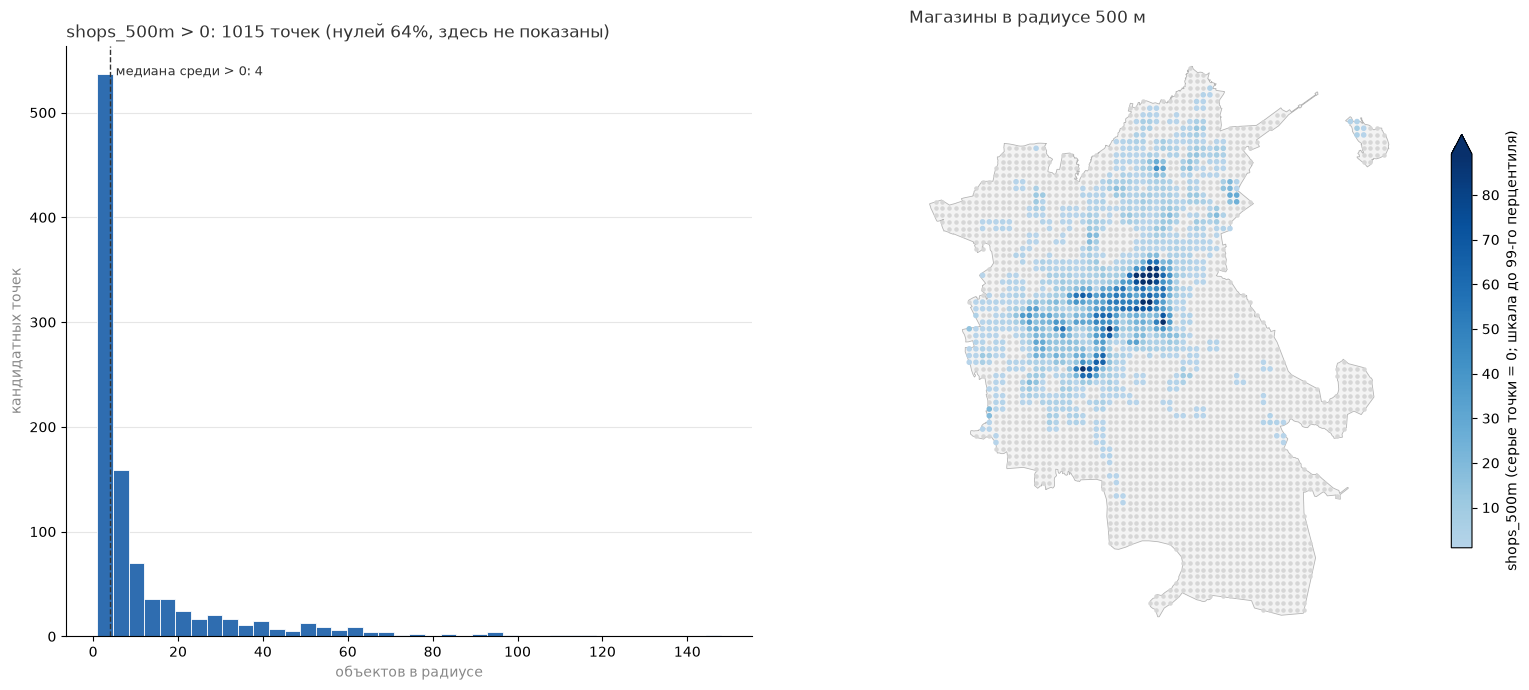

In [11]:
plot_feature(FEATURES["shops_500m"], "shops_500m", "Магазины в радиусе 500 м")

In [12]:
save_feature(FEATURES["shops_500m"], "shops_500m")

сохранено: data\processed\features\shops_500m.csv (2822, 4)


In [13]:
malls = check_geometries(osm[osm["shop"] == "mall"], "malls")
malls_area = malls.assign(area_m2=malls.geometry.area.round())
malls_area.sort_values("area_m2", ascending=False)[["osm_type", "name", "area_m2"]].head(10)

объектов                                  77
пустых геометрий                           0
невалидных геометрий                       0
дублей osm_type+osm_id                     0
одинаковая геометрия у разных объектов     0
типы геометрий: {'MultiPolygon': 68, 'Point': 9}


,osm_type,name,area_m2
133202,relation,Апорт Молл,95789.0
189211,way,Grand Park,78194.0
141580,way,MEGA Alma-Ata,54693.0
263828,way,Aport Mall East,50790.0
133118,relation,Dostyk Plaza,31058.0
290741,way,Алтын Орда,29024.0
196344,way,"""Forum Almaty"" Сауда, Ойын Орталығы",22042.0
205346,way,"ТРЦ ""MART Village""",21380.0
144900,way,"""Mega Park"" СОК",18818.0
141762,way,ADK,17652.0


In [14]:
malls, mall_duplicates = drop_duplicate_objects(malls, max_dist_m=30, unnamed_rule="contained", label="malls")
mall_duplicates

malls: пар-кандидатов 3, склеено 1, оставлены обе 2 {'разные номера дома': 2}
удалено объектов: 1 (в 1 группах); осталось: 76


,osm_1,osm_2,name_1,name_2,address_1,address_2,level_1,level_2,dist_m,решение,причина,map_url
0,way/218948539,way/466832455,Мерей,Мерей,Сүйінбай даңғылы 2/6,NaN,NaN,NaN,0.0,склеено,одно имя,https://www.openstreetmap.org/?mlat=43.273573&...
1,way/219002027,way/253581315,Мерей 1-ші павильон,Мерей 1-ші павильон,Сүйінбай даңғылы 2/3,Сүйінбай даңғылы 2/17,NaN,NaN,0.0,оставлены обе,разные номера дома,https://www.openstreetmap.org/?mlat=43.271474&...
2,way/1090952428,way/1135974828,Алтын Орда,Алтын Орда,Райымбек даңғылы 16к/6,Ташкентский тракт 15 1\\12,NaN,NaN,16.9,оставлены обе,разные номера дома,https://www.openstreetmap.org/?mlat=43.232167&...


count    2822.00
mean        0.35
std         1.17
min         0.00
25%         0.00
50%         0.00
75%         0.00
max        17.00
пропусков: 0 | нулей: 2380 (84.3%)


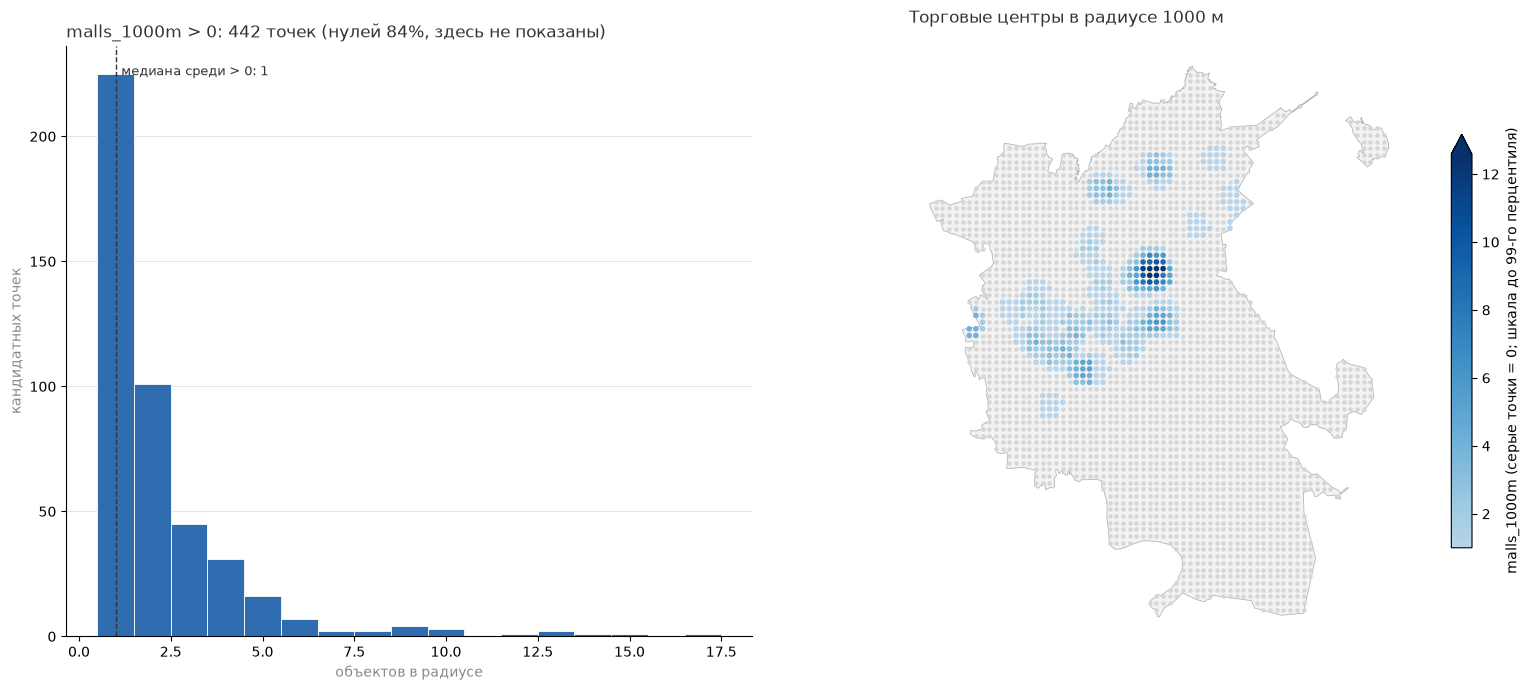

сохранено: data\processed\features\malls_1000m.csv (2822, 4)


In [15]:
FEATURES["malls_1000m"] = count_within(malls, 1000, "malls_1000m", as_points=False)
describe_feature(FEATURES["malls_1000m"], "malls_1000m")
plot_feature(FEATURES["malls_1000m"], "malls_1000m", "Торговые центры в радиусе 1000 м")
save_feature(FEATURES["malls_1000m"], "malls_1000m")

In [16]:
print(osm.loc[osm["amenity"].isin(["restaurant", "fast_food", "food_court", "cafe"]), "amenity"].value_counts().to_string())
print()
restaurants = check_geometries(osm[osm["amenity"] == "restaurant"], "restaurants")
restaurants, restaurant_duplicates = drop_duplicate_objects(
    restaurants, max_dist_m=30, unnamed_rule="contained", label="restaurants"
)
restaurant_duplicates.sort_values("dist_m").head(10)

amenity
cafe          754
restaurant    582
fast_food     449
food_court     11

объектов                                  582
пустых геометрий                            0
невалидных геометрий                        0
дублей osm_type+osm_id                      0
одинаковая геометрия у разных объектов      1
типы геометрий: {'Point': 462, 'MultiPolygon': 120}
restaurants: пар-кандидатов 16, склеено 16, оставлены обе 0
удалено объектов: 14 (в 12 группах); осталось: 568


,osm_1,osm_2,name_1,name_2,address_1,address_2,level_1,level_2,dist_m,решение,причина,map_url
0,node/2377928007,way/155240520,NaN,Достар,NaN,NaN,NaN,NaN,0.0,склеено,"без имени, внутри объекта той же категории",https://www.openstreetmap.org/?mlat=43.382710&...
1,node/3126151858,way/552773779,Жулдыз,NaN,NaN,Гоголь көшесі 40,1,NaN,0.0,склеено,"без имени, внутри объекта той же категории",https://www.openstreetmap.org/?mlat=43.259970&...
2,node/3265597309,way/229564461,Konya Gunaydin,Konya Gunaydin,Абай даңғылы 30а,3-ий микрорайон 30А,NaN,NaN,0.0,склеено,одно имя,https://www.openstreetmap.org/?mlat=43.222593&...
3,node/3724972367,way/1454393219,Теплица,NaN,NaN,NaN,NaN,NaN,0.0,склеено,"без имени, внутри объекта той же категории",https://www.openstreetmap.org/?mlat=43.245618&...
4,node/4213978289,way/60064466,Турандот,Турандот,NaN,Жароков көшесі 282,NaN,NaN,0.0,склеено,одно имя,https://www.openstreetmap.org/?mlat=43.206243&...
5,node/4526603857,way/166814190,Tirol,NaN,Жібек Жолы даңғылы 98,улица Жибек Жолы 98,NaN,NaN,0.0,склеено,"без имени, внутри объекта той же категории",https://www.openstreetmap.org/?mlat=43.261500&...
6,node/5325051922,way/1202894480,NaN,NaN,NaN,NaN,NaN,NaN,0.0,склеено,"без имени, внутри объекта той же категории",https://www.openstreetmap.org/?mlat=43.293237&...
7,node/7638501586,way/817900311,Саудабай,Саудабай,NaN,NaN,NaN,NaN,0.0,склеено,одно имя,https://www.openstreetmap.org/?mlat=43.168328&...
11,node/9700570001,relation/8810349,White Elephant,NaN,Әуезов көшесі 42,улица Тимирязева,NaN,NaN,0.0,склеено,"без имени, внутри объекта той же категории",https://www.openstreetmap.org/?mlat=43.224854&...
10,node/7638501588,way/817900310,Саудабай,Саудабай,NaN,NaN,NaN,NaN,0.0,склеено,одно имя,https://www.openstreetmap.org/?mlat=43.168376&...


count    2822.00
mean        0.60
std         2.33
min         0.00
25%         0.00
50%         0.00
75%         0.00
max        33.00
пропусков: 0 | нулей: 2371 (84.0%)


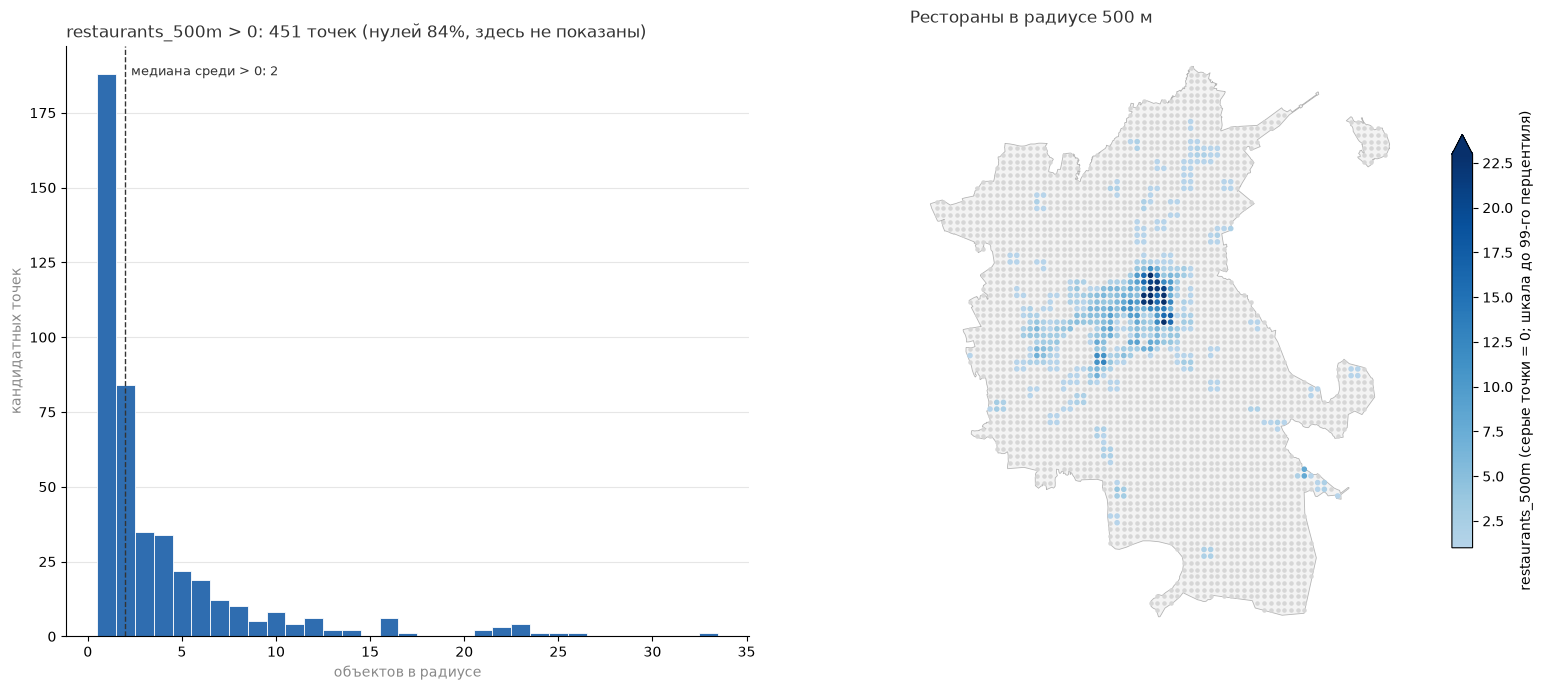

сохранено: data\processed\features\restaurants_500m.csv (2822, 4)


In [17]:
FEATURES["restaurants_500m"] = count_within(restaurants, 500, "restaurants_500m", as_points=True)
describe_feature(FEATURES["restaurants_500m"], "restaurants_500m")
plot_feature(FEATURES["restaurants_500m"], "restaurants_500m", "Рестораны в радиусе 500 м")
save_feature(FEATURES["restaurants_500m"], "restaurants_500m")

In [18]:
def select_metro(gdf):
    '''Действующие станции метро: railway=station + station=subway, без construction.'''
    return gdf[(gdf["railway"] == "station") & (gdf["station"] == "subway") & gdf["construction"].isna()]


print("строящиеся (не берём):", sorted(metro_wide.loc[metro_wide["construction"].notna(), "name"].dropna().unique()))
metro = check_geometries(select_metro(metro_wide), "metro_stations")
metro, metro_duplicates = drop_duplicate_objects(metro, max_dist_m=300, unnamed_rule="nearby", label="metro")
assert metro["name"].is_unique
metro[["osm_type", "osm_id", "name", "name:ru"]]

строящиеся (не берём): ['Қалқаман']
объектов                                  11
пустых геометрий                           0
невалидных геометрий                       0
дублей osm_type+osm_id                     0
одинаковая геометрия у разных объектов     0
типы геометрий: {'Point': 11}
metro: пар-кандидатов 0, склеено 0, оставлены обе 0
удалено объектов: 0 (в 0 группах); осталось: 11


,osm_type,osm_id,name,name:ru
0,node,2522351049,Абай,Абая
1,node,2522351050,Алатау,Алатау
2,node,2522351052,Байқоңыр,Байконур
3,node,2522351053,Жібек Жолы,Жибек Жолы
4,node,2522351055,Мұхтар Әуезов атындағы театры,Театр имени Мухтара Ауэзова
5,node,3464799078,Мәскеу,Москва
6,node,3464799079,Сайран,Сайран
7,node,9346636498,Райымбек батыр,Райымбек батыра
8,node,11496660771,Алмалы,Алмалы
9,node,13603952093,Бауыржан Момышұлы,Бауржан Момышулы


metro_dist: до края вырезки у всех точек остаётся не меньше 4.7 км
count     2822.00
mean      9027.62
std       5720.30
min         87.90
25%       4532.20
50%       8106.30
75%      12536.92
max      25253.50
пропусков: 0 | нулей: 0 (0.0%)
точек не дальше 500 м от метро: 36
точек не дальше 1000 м от метро: 105
точек не дальше 2000 м от метро: 249


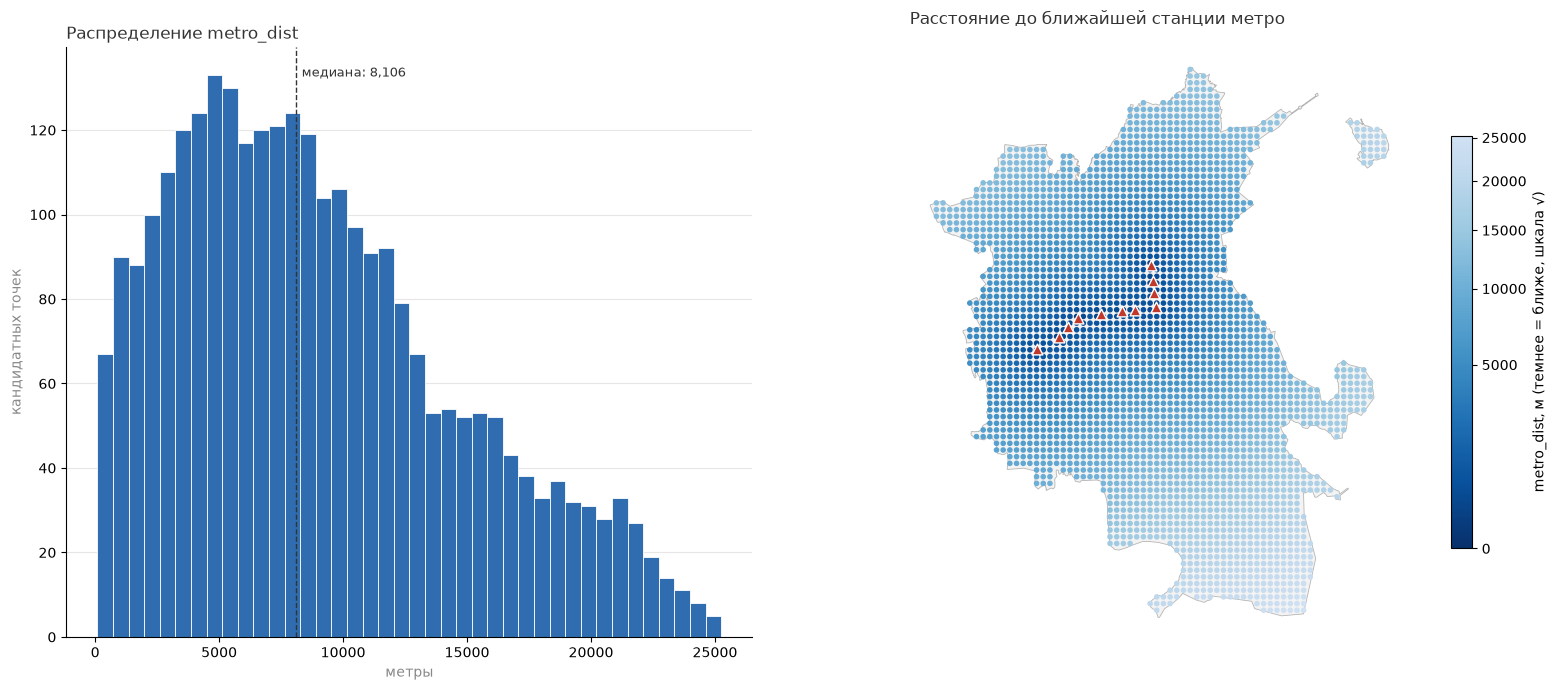

сохранено: data\processed\features\metro_dist.csv (2822, 4)


In [19]:
FEATURES["metro_dist"] = nearest_distance(metro, "metro_dist", distance_area)
describe_feature(FEATURES["metro_dist"], "metro_dist")
for limit in (500, 1000, 2000):
    print(f"точек не дальше {limit} м от метро: {(FEATURES['metro_dist']['metro_dist'] <= limit).sum()}")
plot_feature(FEATURES["metro_dist"], "metro_dist", "Расстояние до ближайшей станции метро", distance=True,
             overlay=metro, overlay_style={"color": "#c0392b", "marker": "^", "markersize": 60, "edgecolor": "white"})
save_feature(FEATURES["metro_dist"], "metro_dist")

| что | теги | как считаем |
|---|---|---|
| автобус/троллейбус, место ожидания | `highway=bus_stop` или `public_transport=platform` (не метро и не ж/д); `bus=no` без `trolleybus=yes` не берём | основной объект остановки |
| точка остановки на дороге | `public_transport=stop_position` (то же правило `bus=no`) | дубль платформы, только если рядом есть «своя» платформа (см. ниже); иначе берём |
| метро | 11 станций из раздела метро | одна станция = одна остановка |
| пригородная/ж/д станция | пассажирская `railway=station/halt`, не метро | склеиваем одноимённые в пределах 300 м |

 Столб `highway=bus_stop` и полигон/линия платформы рядом — одна остановка. Склеиваем пары в пределах 10 м с совпадающим именем или если у одной нет имени, **но только если между ними нет проезжей части**.

**`stop_position`** лежит на оси дороги. Она дублирует платформу, только если рядом есть «своя» платформа: не дальше 30 м, отрезок до неё не пересекает ось другой проезжей части, и эта платформа ещё не сопоставлена другой `stop_position` (одна платформа — одно направление — одна точка остановки). Проезды `highway=service` (заездные карманы, дублёры) стороны улицы не разделяют. Поэтому `stop_position` не удаляется из-за платформы через дорогу. Пересечения осей ближе 1 м от концов отрезка не считаются: так узел на собственной дороге из-за округления координат не «пересекает» её. Статус каждой `stop_position` — в `data/processed/qa/stop_positions.csv`.

**Ж/д станции** берём только пассажирские (`public_transport=station` или `railway=halt`).

In [20]:
# оси проезжих частей, которые делят улицу на стороны; проезды highway=service (заездные карманы, дублёры,
# парковочные аллеи) стороны не разделяют
CAR_ROADS = ["motorway", "trunk", "primary", "secondary", "tertiary", "unclassified", "residential", "living_street",
             "motorway_link", "trunk_link", "primary_link", "secondary_link", "tertiary_link"]
road_axes = osm[osm["highway"].isin(CAR_ROADS) & (osm.geom_type == "LineString")]

is_metro_or_rail = osm["subway"].notna() | osm["railway"].notna()
not_bus_or_trolleybus = (osm["bus"] == "no") & (osm["trolleybus"] != "yes")
platform_like = (osm["highway"] == "bus_stop") | ((osm["public_transport"] == "platform") & ~is_metro_or_rail)
stop_position_like = (osm["public_transport"] == "stop_position") & (osm["highway"] != "bus_stop") & ~is_metro_or_rail
print("bus=no без trolleybus=yes (не берём):",
      osm.loc[(platform_like | stop_position_like) & not_bus_or_trolleybus, ["osm_type", "osm_id", "name"]]
         .assign(osm=lambda t: t["osm_type"] + "/" + t["osm_id"].astype(str))[["osm", "name"]].to_dict("records"))

platforms_raw = osm[platform_like & ~not_bus_or_trolleybus]
stop_positions = osm[stop_position_like & ~not_bus_or_trolleybus].reset_index(drop=True)
rail_raw = osm[
    osm["railway"].isin(["station", "halt"]) & (osm["station"] != "subway") & osm["construction"].isna()
    & ((osm["public_transport"] == "station") | (osm["railway"] == "halt"))
]

platforms = check_geometries(platforms_raw, "bus_trolleybus_platforms")
platforms, platform_duplicates = drop_duplicate_objects(
    platforms, max_dist_m=10, unnamed_rule="nearby", barriers=road_axes, label="bus_platforms"
)
platform_duplicates.sort_values("dist_m", ascending=False).head(8)

bus=no без trolleybus=yes (не берём): [{'osm': 'node/10697961891', 'name': 'Ущелье Аюсай'}]
объектов                                  2229
пустых геометрий                             0
невалидных геометрий                         0
дублей osm_type+osm_id                       0
одинаковая геометрия у разных объектов       0
типы геометрий: {'Point': 2168, 'MultiPolygon': 34, 'LineString': 27}


bus_platforms: пар-кандидатов 143, склеено 112, оставлены обе 31 {'через дорогу': 31}
удалено объектов: 99 (в 82 группах); осталось: 2130


,osm_1,osm_2,name_1,name_2,address_1,address_2,level_1,level_2,dist_m,решение,причина,map_url
4,node/1140353376,node/12615267334,2-й микрорайон,2-й микрорайон,NaN,NaN,NaN,NaN,10.0,оставлены обе,через дорогу,https://www.openstreetmap.org/?mlat=43.236022&...
75,node/11564373649,node/11564373653,Каменское плато,Каменское плато,NaN,NaN,NaN,NaN,9.9,оставлены обе,через дорогу,https://www.openstreetmap.org/?mlat=43.187444&...
26,node/2829357385,node/14365179958,NaN,NaN,NaN,NaN,NaN,NaN,9.9,склеено,"без имени, рядом с объектом той же категории",https://www.openstreetmap.org/?mlat=43.227092&...
109,node/14143600700,node/14143920560,Яссауи/Шаляпин,Яссауи/Шаляпин,NaN,NaN,NaN,NaN,9.9,оставлены обе,через дорогу,https://www.openstreetmap.org/?mlat=43.209230&...
100,node/13521882842,node/13521882846,Райымбек даңғылы,Райымбек даңғылы,NaN,NaN,NaN,NaN,9.8,оставлены обе,через дорогу,https://www.openstreetmap.org/?mlat=43.269387&...
86,node/12531397758,node/13290408431,Самал мейрамханасы,Самал мейрамханасы,NaN,NaN,NaN,NaN,9.7,склеено,одно имя,https://www.openstreetmap.org/?mlat=43.172298&...
113,node/14331429614,node/14331429615,По требованию,По требованию,NaN,NaN,NaN,NaN,9.7,оставлены обе,через дорогу,https://www.openstreetmap.org/?mlat=43.221548&...
74,node/11366646012,node/12827588648,Комплекс Султан,Комплекс Султан,NaN,NaN,NaN,NaN,9.7,оставлены обе,через дорогу,https://www.openstreetmap.org/?mlat=43.336710&...


In [21]:
# stop_position — дубль платформы, если рядом «своя» платформа: <= 30 м, не через ось другой дороги
# и ещё не сопоставленная другой stop_position. Пары перебираются от ближайших (жадное сопоставление 1:1).
sp_geoms = np.asarray(stop_positions.geometry.array)
pl_geoms = np.asarray(platforms.geometry.array)
sp_idx, pl_idx = platforms.sindex.query(stop_positions.geometry, predicate="dwithin", distance=30)
across = separated_by_road(sp_geoms[sp_idx], shapely.point_on_surface(pl_geoms[pl_idx]), road_axes)
pair_dist = shapely.distance(sp_geoms[sp_idx], pl_geoms[pl_idx])
matched_sp, matched_pl = set(), set()
for k in np.lexsort((pl_idx, sp_idx, pair_dist)):
    if across[k] or sp_idx[k] in matched_sp or pl_idx[k] in matched_pl:
        continue
    matched_sp.add(int(sp_idx[k]))
    matched_pl.add(int(pl_idx[k]))

positions = np.arange(len(stop_positions))
matched = np.isin(positions, list(matched_sp))
near_any = np.isin(positions, sp_idx)
near_same_side = np.isin(positions, sp_idx[~across])
stop_positions["status"] = np.select(
    [matched, ~near_any, ~near_same_side],
    ["дубль своей платформы (не берём)", "платформы нет ближе 30 м", "платформа только через дорогу"],
    default="своя платформа уже сопоставлена другой stop_position",
)
stop_positions.assign(osm=osm_refs(stop_positions))[["osm", "name", "status"]].to_csv(
    QA_DIR / "stop_positions.csv", index=False, lineterminator="\n")
orphan_stop_positions = stop_positions[~matched]
print(stop_positions["status"].value_counts().to_string())

rail = check_geometries(rail_raw, "rail_stations")
rail, rail_duplicates = drop_duplicate_objects(rail, max_dist_m=300, unnamed_rule="nearby", label="rail")
print("ж/д станции:", sorted(rail["name"].dropna()))

transit_stops = pd.concat([
    platforms.assign(stop_kind="bus/trolleybus"),
    orphan_stop_positions.assign(stop_kind="bus/trolleybus (stop_position)"),
    metro.assign(stop_kind="metro"),
    rail.assign(stop_kind="rail"),
], ignore_index=True)
transit_stops = gpd.GeoDataFrame(transit_stops[["osm_type", "osm_id", "name", "stop_kind", "geometry"]],
                                 geometry="geometry", crs=CRS_METRIC)
transit_stops["stop_kind"].value_counts().to_frame()

status
дубль своей платформы (не берём)                        856
платформы нет ближе 30 м                                  5
платформа только через дорогу                             4
своя платформа уже сопоставлена другой stop_position      3
объектов                                  9
пустых геометрий                          0
невалидных геометрий                      0
дублей osm_type+osm_id                    0
одинаковая геометрия у разных объектов    0
типы геометрий: {'Point': 7, 'MultiPolygon': 2}
rail: пар-кандидатов 1, склеено 1, оставлены обе 0
удалено объектов: 1 (в 1 группах); осталось: 8
ж/д станции: ['Алматы-1', 'Алматы-2', 'Баум тоғайы', 'Боралдай', 'Индустриальная', 'Көкөзек', 'Отыз', 'Әуеайлақ']


,count
stop_kind,
bus/trolleybus,2130
bus/trolleybus (stop_position),12
metro,11
rail,8


In [22]:
FEATURES["transit_stops_500m"] = count_within(transit_stops, 500, "transit_stops_500m", as_points=True)
describe_feature(FEATURES["transit_stops_500m"], "transit_stops_500m")

# сравнение с bus_stops_500m, посчитанным как в 02 (узлы highway=bus_stop внутри границы города, без дедупликации)
bus_stops_02 = osm[(osm["highway"] == "bus_stop") & osm.intersects(city_geometry)]
bus_stops_like_02 = count_within(bus_stops_02, 500, "bus_stops_500m_like_02")
pair = FEATURES["transit_stops_500m"].merge(bus_stops_like_02, on="candidate_id")
print("\nкорреляция с bus_stops_500m (как в 02): Pearson "
      f"{pair['transit_stops_500m'].corr(pair['bus_stops_500m_like_02']):.3f}, "
      f"Spearman {pair['transit_stops_500m'].corr(pair['bus_stops_500m_like_02'], method='spearman'):.3f}")

count    2822.00
mean        2.24
std         3.54
min         0.00
25%         0.00
50%         0.00
75%         4.00
max        25.00
пропусков: 0 | нулей: 1574 (55.8%)



корреляция с bus_stops_500m (как в 02): Pearson 0.990, Spearman 0.995


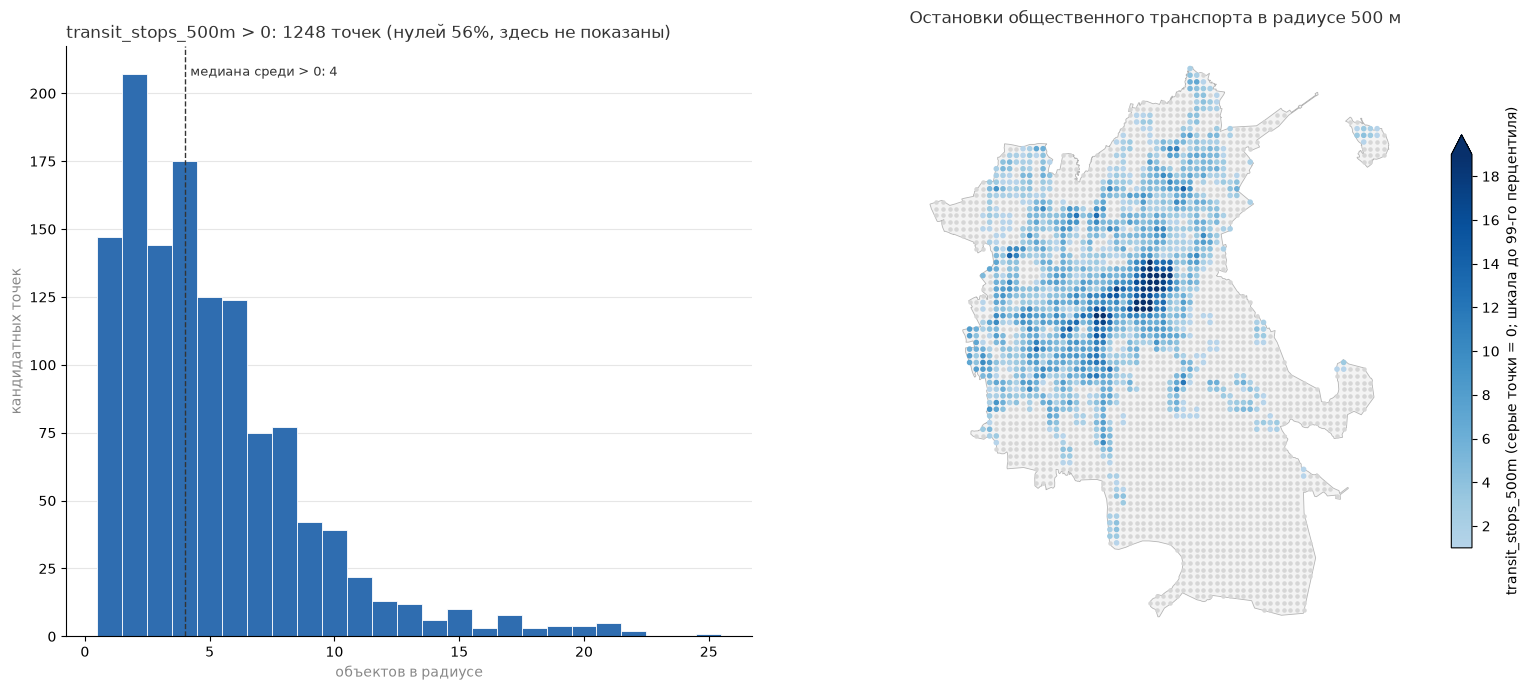

сохранено: data\processed\features\transit_stops_500m.csv (2822, 4)


In [23]:
plot_feature(FEATURES["transit_stops_500m"], "transit_stops_500m", "Остановки общественного транспорта в радиусе 500 м")
save_feature(FEATURES["transit_stops_500m"], "transit_stops_500m")

In [24]:
print(osm.loc[osm["amenity"].isin(["parking", "parking_entrance", "parking_space"]), "amenity"].value_counts().to_string())
parking_raw = osm[osm["amenity"] == "parking"]
print("\naccess:", parking_raw["access"].value_counts(dropna=False).to_dict())
print("parking:", parking_raw["parking"].value_counts(dropna=False).to_dict())

PARKING_EXCLUDE_ACCESS = {"private", "no", "residents"}
PARKING_EXCLUDE_TYPE = {"garage_boxes", "carports"}
excluded = parking_raw["access"].isin(PARKING_EXCLUDE_ACCESS) | parking_raw["parking"].isin(PARKING_EXCLUDE_TYPE)
print("исключено:", int(excluded.sum()))
print()
parking = check_geometries(parking_raw[~excluded], "parking")
parking, parking_duplicates = drop_duplicate_objects(parking, max_dist_m=5, unnamed_rule="contained", label="parking")
print("площадь полигонов парковок, м²:",
      parking.loc[parking.geom_type != "Point"].geometry.area.describe().round().to_dict())

amenity
parking             2461
parking_entrance     123
parking_space         23

access: {nan: 2053, 'yes': 263, 'customers': 72, 'private': 48, 'permissive': 13, 'no': 6, 'permit': 4, 'residents': 2}
parking: {nan: 1754, 'surface': 541, 'street_side': 87, 'underground': 47, 'lane': 16, 'multi-storey': 8, 'carports': 2, 'garage': 1, 'garage_boxes': 1, 'rooftop': 1, 'shoulder': 1, 'half_on_kerb': 1, 'yes': 1}
исключено: 59

объектов                                  2402
пустых геометрий                             0
невалидных геометрий                         0
дублей osm_type+osm_id                       0
одинаковая геометрия у разных объектов       0
типы геометрий: {'MultiPolygon': 2156, 'Point': 246}


parking: пар-кандидатов 10, склеено 10, оставлены обе 0
удалено объектов: 10 (в 10 группах); осталось: 2392
площадь полигонов парковок, м²: {'count': 2153.0, 'mean': 1389.0, 'std': 3178.0, 'min': 15.0, '25%': 259.0, '50%': 572.0, '75%': 1332.0, 'max': 58393.0}


count    2822.00
mean        2.76
std         7.30
min         0.00
25%         0.00
50%         0.00
75%         2.00
max        84.00
пропусков: 0 | нулей: 1716 (60.8%)


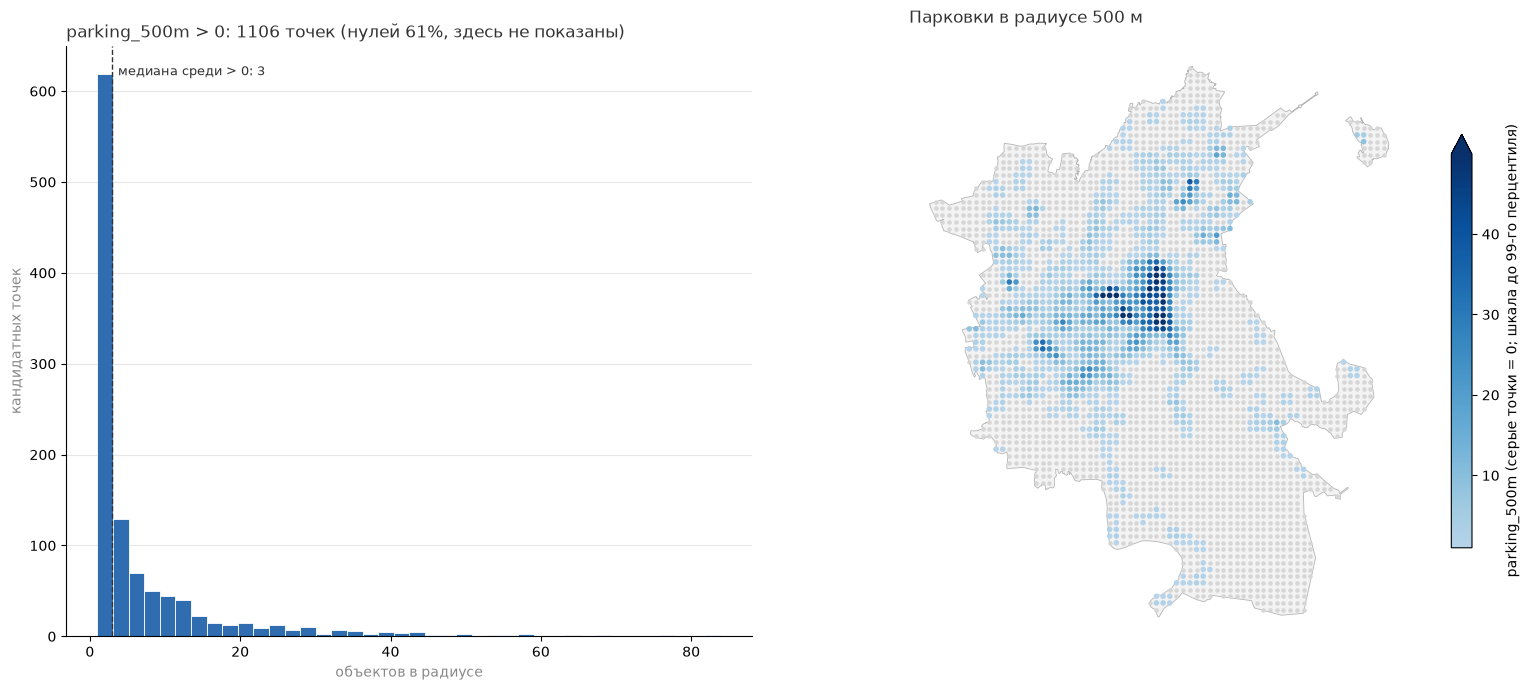

сохранено: data\processed\features\parking_500m.csv (2822, 4)


In [25]:
FEATURES["parking_500m"] = count_within(parking, 500, "parking_500m", as_points=False)
describe_feature(FEATURES["parking_500m"], "parking_500m")
plot_feature(FEATURES["parking_500m"], "parking_500m", "Парковки в радиусе 500 м")
save_feature(FEATURES["parking_500m"], "parking_500m")

Линии `highway=motorway/trunk/primary/secondary` (магистрали, ВОАД, проспекты, крупные улицы) — из отдельной широкой вырезки (город + 30 км). В зоне «город + 2 км» ближайшая крупная дорога для части окраинных точек лежала за краем вырезки, и расстояние получалось завышенным. Участки в тоннелях не берём.

In [26]:
def select_major_roads(gdf):
    '''Крупные дороги (только линии), без участков в тоннелях.'''
    lines = gdf[gdf["highway"].isin(MAJOR_HIGHWAYS) & gdf.geom_type.isin(["LineString", "MultiLineString"])]
    return lines[~lines["tunnel"].isin(["yes", "building_passage"])]


in_tunnel = major_roads_wide["tunnel"].isin(["yes", "building_passage"])
print(f"сегментов в тоннеле (исключаем): {in_tunnel.sum()}, {major_roads_wide[in_tunnel].length.sum() / 1000:.1f} км")
roads = check_geometries(select_major_roads(major_roads_wide), "major_roads")
(roads.assign(length_km=roads.length / 1000)
      .groupby("highway").agg(segments=("osm_id", "size"), length_km=("length_km", "sum"))
      .round(1).reindex(MAJOR_HIGHWAYS))

сегментов в тоннеле (исключаем): 66, 3.2 км
объектов                                  4144
пустых геометрий                             0
невалидных геометрий                         0
дублей osm_type+osm_id                       0
одинаковая геометрия у разных объектов       0
типы геометрий: {'LineString': 4144}


,segments,length_km
highway,,
motorway,264,287.9
trunk,80,119.3
primary,1393,543.4
secondary,2407,734.9


major_roads_distance: до края вырезки у всех точек остаётся не меньше 16.0 км
count     2822.00
mean      2264.61
std       2846.72
min          0.30
25%        256.02
50%       1023.15
75%       3295.50
max      13975.80
пропусков: 0 | нулей: 0 (0.0%)
точек не дальше 100 м от крупной дороги: 309
точек не дальше 250 м от крупной дороги: 693
точек не дальше 500 м от крупной дороги: 1042


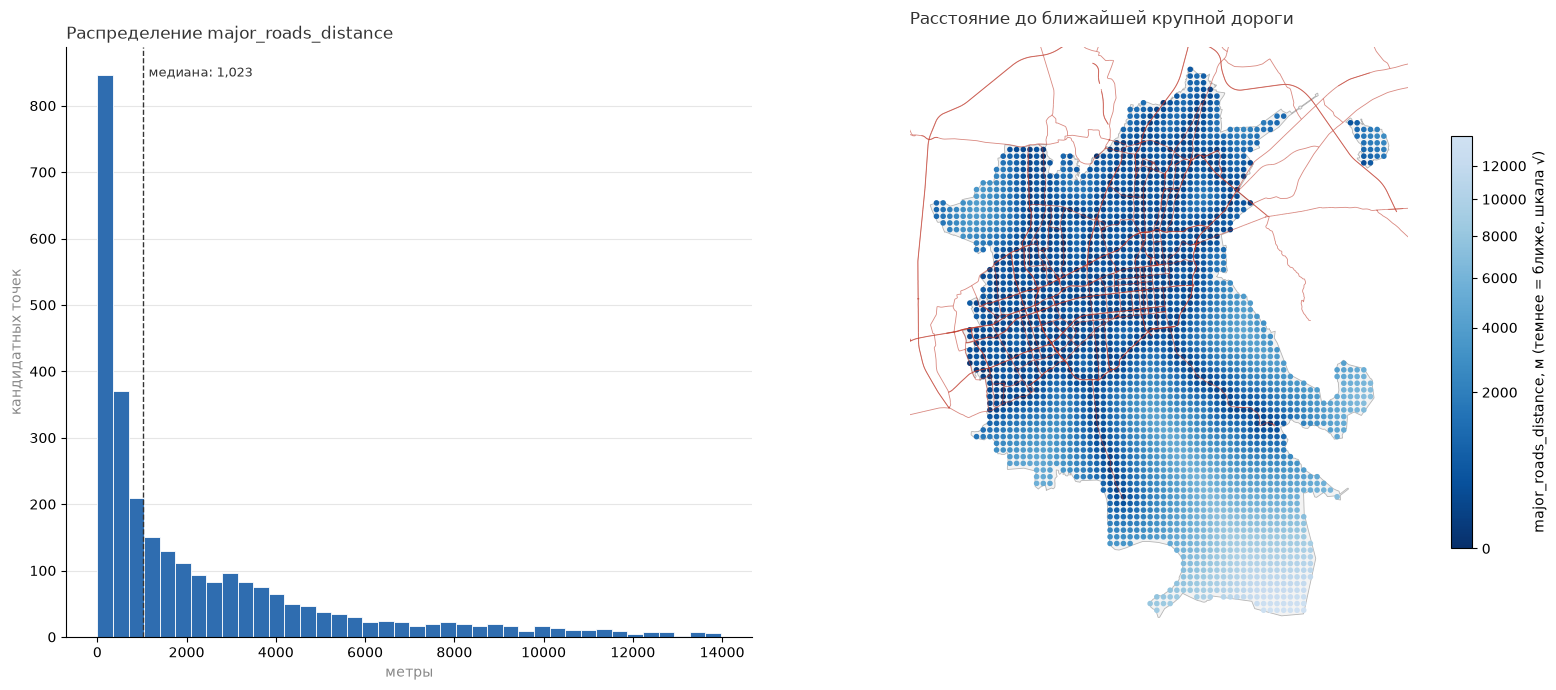

сохранено: data\processed\features\major_roads_distance.csv (2822, 4)


In [27]:
FEATURES["major_roads_distance"] = nearest_distance(roads, "major_roads_distance", distance_area)
describe_feature(FEATURES["major_roads_distance"], "major_roads_distance")
for limit in (100, 250, 500):
    print(f"точек не дальше {limit} м от крупной дороги: {(FEATURES['major_roads_distance']['major_roads_distance'] <= limit).sum()}")
plot_feature(FEATURES["major_roads_distance"], "major_roads_distance", "Расстояние до ближайшей крупной дороги",
             distance=True, overlay=roads, overlay_style={"color": "#c0392b", "linewidth": 0.6, "alpha": 0.6})
save_feature(FEATURES["major_roads_distance"], "major_roads_distance")

**Проверка расстояний.** Крупные дороги и станции метро перечитываются прямо из PBF в зоне «город + 60 км» (вдвое шире), и `major_roads_distance`, `metro_dist` считаются заново. Если вырезки +30 км достаточно, значения совпадают у всех 2 822 точек. Для сравнения — сколько точек получали завышенное расстояние при прежней зоне «город + 2 км».

In [28]:
if VERIFY_DISTANCES:
    wider_area = city_geometry.buffer(2 * DISTANCE_BUFFER_M)
    wider_bbox = tuple(gpd.GeoSeries([wider_area], crs=CRS_METRIC).to_crs(4326).total_bounds)

    def read_pbf_layer(layer):
        source_layer, _, where = EXTRACT_LAYERS[layer]
        raw = pyogrio.read_dataframe(PBF_PATH, layer=source_layer, bbox=wider_bbox, where=where)
        return to_osm_frame(raw, source_layer, wider_area)

    start = time.time()
    rows = []
    for name, objects in (("major_roads_distance", select_major_roads(read_pbf_layer("major_roads"))),
                          ("metro_dist", select_metro(read_pbf_layer("metro_stations")))):
        current = FEATURES[name][name]
        wider = nearest_distance(objects, name, wider_area)[name]
        narrow = nearest_distance(objects[objects.intersects(study_area)], name, study_area, check_edge=False)[name]
        diff = (wider - current).abs()
        overshoot = narrow - current
        rows.append({
            "признак": name,
            "отличий от вырезки ×2": int((diff > 0).sum()),
            "макс. разница с вырезкой ×2, м": float(diff.max()),
            "точек с завышением при +2 км": int((overshoot > 0).sum()),
            "макс. завышение при +2 км, м": float(overshoot.max()),
        })
        assert (diff == 0).all(), f"{name}: значения зависят от ширины вырезки"
    print(f"перечитано из PBF за {time.time() - start:.0f} с")
    display(pd.DataFrame(rows))

major_roads_distance: до края вырезки у всех точек остаётся не меньше 46.0 км
metro_dist: до края вырезки у всех точек остаётся не меньше 34.7 км
перечитано из PBF за 21 с


,признак,отличий от вырезки ×2,"макс. разница с вырезкой ×2, м",точек с завышением при +2 км,"макс. завышение при +2 км, м"
0,major_roads_distance,0,0.0,47,1899.4
1,metro_dist,0,0.0,0,0.0



- `tourism`: `attraction`, `museum`, `gallery`, `theme_park`, `zoo`, `aquarium`;
- `historic`: `monument`, `memorial`, `castle`, `ruins`, `archaeological_site`, `manor`, `fort`, `building`, `church`, `tomb`, `house`.



In [29]:
ATTRACTION_TOURISM = {"attraction", "museum", "gallery", "theme_park", "zoo", "aquarium"}
ATTRACTION_HISTORIC = {"monument", "memorial", "castle", "ruins", "archaeological_site", "manor", "fort",
                       "building", "church", "tomb", "house"}
MEMORIAL_EXCLUDE = {"plaque", "blue_plaque"}

tourism_ok = osm["tourism"].isin(ATTRACTION_TOURISM)
historic_ok = osm["historic"].isin(ATTRACTION_HISTORIC) & ~osm["memorial"].isin(MEMORIAL_EXCLUDE)
attractions_raw = osm[tourism_ok | historic_ok].copy()
attractions_raw["attraction_type"] = attractions_raw["tourism"].where(
    attractions_raw["tourism"].isin(ATTRACTION_TOURISM), attractions_raw["historic"]
)
not_taken = osm[(osm["tourism"].notna() | osm["historic"].notna()) & ~(tourism_ok | historic_ok)]
not_taken_label = ("tourism=" + not_taken["tourism"]).fillna("historic=" + not_taken["historic"] + "/" + not_taken["memorial"].fillna("-"))
print("не взяли (топ):", not_taken_label.value_counts().head(8).to_dict())
print()
attractions = check_geometries(attractions_raw, "attractions")
attractions, attraction_duplicates = drop_duplicate_objects(
    attractions, max_dist_m=30, unnamed_rule="contained", category_col="attraction_type", label="attractions"
)
attractions["attraction_type"].value_counts().to_frame().T

не взяли (топ): {'tourism=information': 361, 'tourism=artwork': 271, 'tourism=hotel': 163, 'historic=memorial/plaque': 106, 'tourism=viewpoint': 103, 'tourism=hostel': 87, 'tourism=camp_site': 81, 'tourism=picnic_site': 38}

объектов                                  316
пустых геометрий                            0
невалидных геометрий                        0
дублей osm_type+osm_id                      0
одинаковая геометрия у разных объектов      0
типы геометрий: {'Point': 228, 'MultiPolygon': 87, 'LineString': 1}


attractions: пар-кандидатов 16, склеено 10, оставлены обе 6 {'разные категории': 6}
удалено объектов: 10 (в 9 группах); осталось: 306


attraction_type,memorial,attraction,monument,museum,theme_park,gallery,zoo,tomb,manor,ruins,building,archaeological_site
count,148,76,28,21,7,7,5,4,4,3,2,1


count    2822.00
mean        1.30
std         6.12
min         0.00
25%         0.00
50%         0.00
75%         1.00
max       101.00


пропусков: 0 | нулей: 1974 (70.0%)


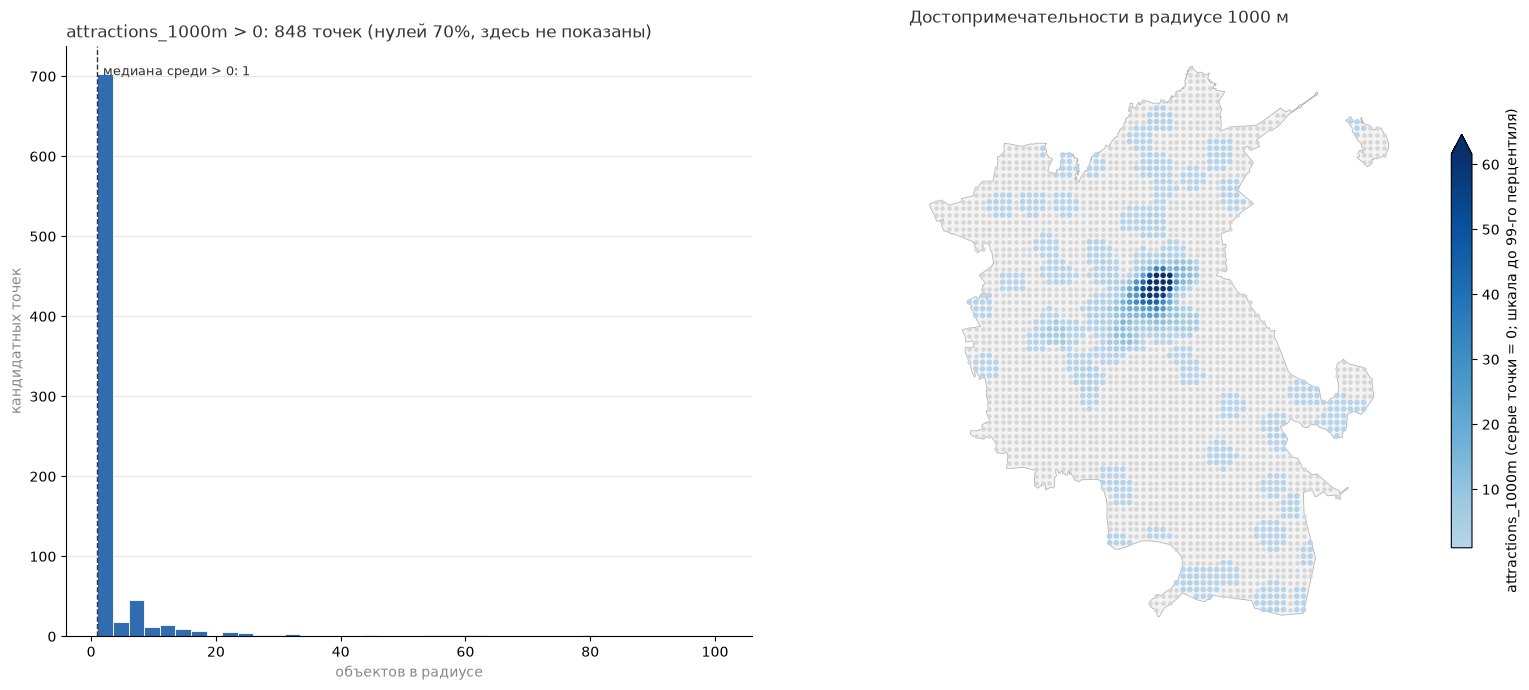

сохранено: data\processed\features\attractions_1000m.csv (2822, 4)


In [30]:
FEATURES["attractions_1000m"] = count_within(attractions, 1000, "attractions_1000m", as_points=False)
describe_feature(FEATURES["attractions_1000m"], "attractions_1000m")
plot_feature(FEATURES["attractions_1000m"], "attractions_1000m", "Достопримечательности в радиусе 1000 м")
save_feature(FEATURES["attractions_1000m"], "attractions_1000m")

In [31]:
FEATURE_ORDER = ["shops_500m", "malls_1000m", "restaurants_500m", "metro_dist",
                 "transit_stops_500m", "parking_500m", "major_roads_distance", "attractions_1000m"]

osm_features = candidates[["candidate_id", "x", "y"]].copy()
for name in FEATURE_ORDER:
    osm_features = osm_features.merge(FEATURES[name], on="candidate_id", how="left", validate="one_to_one")

assert osm_features.shape == (N_CANDIDATES, 3 + len(FEATURE_ORDER))
assert osm_features["candidate_id"].is_unique
assert osm_features.isna().sum().sum() == 0

combined_path = FEATURES_DIR / "osm_commercial_features.csv"
osm_features.to_csv(combined_path, index=False, lineterminator="\n")
features_sha256 = hashlib.sha256(combined_path.read_bytes()).hexdigest()
print("сохранено:", combined_path.relative_to(PROJECT_ROOT), osm_features.shape)
print("sha256 признаков:", features_sha256, "| PBF md5:", pbf_md5, "| граница sha256:", boundary_sha256[:12])
osm_features[FEATURE_ORDER].describe().T.round(1)

сохранено: data\processed\features\osm_commercial_features.csv (2822, 11)
sha256 признаков: bc82df51da6cd84e3cb134180fcf745f477a66be5de89b9da476e07e76669a79 | PBF md5: 57fd297ad55df539e0ec233312922ca0 | граница sha256: e5f3da403469


,count,mean,std,min,25%,50%,75%,max
shops_500m,2822.0,4.1,12.0,0.0,0.0,0.0,2.0,148.0
malls_1000m,2822.0,0.4,1.2,0.0,0.0,0.0,0.0,17.0
restaurants_500m,2822.0,0.6,2.3,0.0,0.0,0.0,0.0,33.0
metro_dist,2822.0,9027.6,5720.3,87.9,4532.2,8106.3,12536.9,25253.5
transit_stops_500m,2822.0,2.2,3.5,0.0,0.0,0.0,4.0,25.0
parking_500m,2822.0,2.8,7.3,0.0,0.0,0.0,2.0,84.0
major_roads_distance,2822.0,2264.6,2846.7,0.3,256.0,1023.2,3295.5,13975.8
attractions_1000m,2822.0,1.3,6.1,0.0,0.0,0.0,1.0,101.0


In [32]:
pd.DataFrame({
    "пропусков": osm_features[FEATURE_ORDER].isna().sum(),
    "доля нулей": (osm_features[FEATURE_ORDER] == 0).mean().round(3),
})

,пропусков,доля нулей
shops_500m,0,0.640
malls_1000m,0,0.843
restaurants_500m,0,0.840
metro_dist,0,0.000
transit_stops_500m,0,0.558
parking_500m,0,0.608
major_roads_distance,0,0.000
attractions_1000m,0,0.700


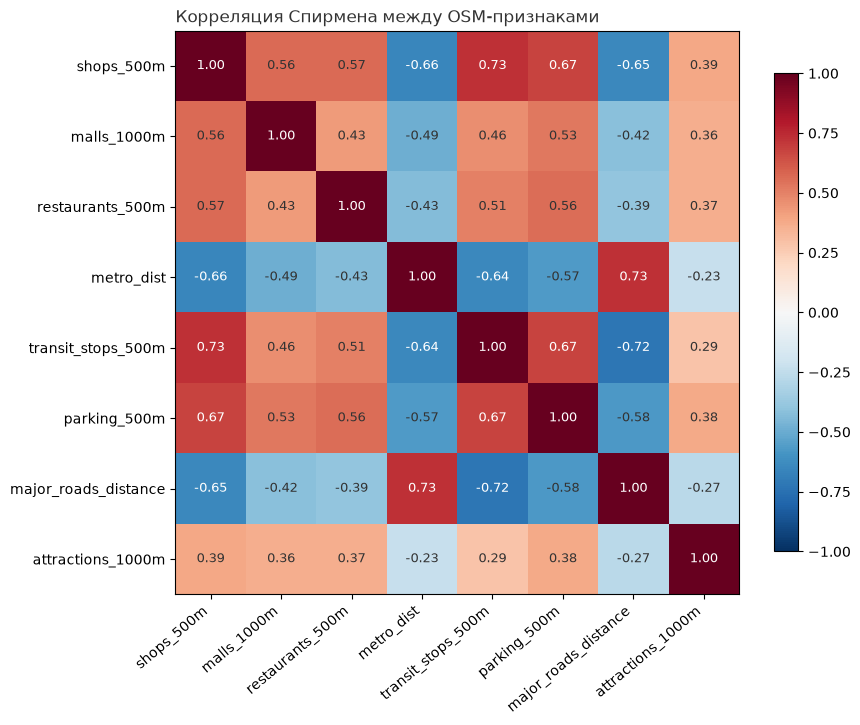

In [33]:
# корреляции какие признаки дублируют друг друга
corr = osm_features[FEATURE_ORDER].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_ORDER)), FEATURE_ORDER, rotation=40, ha="right")
ax.set_yticks(range(len(FEATURE_ORDER)), FEATURE_ORDER)
for i in range(len(FEATURE_ORDER)):
    for j in range(len(FEATURE_ORDER)):
        value = corr.iat[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(value) > 0.6 else INK)
ax.set_title("Корреляция Спирмена между OSM-признаками", loc="left", color=INK)
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**Объединение с сеткой.** `attach_features` присоединяет CSV к `candidate_locations.gpkg` из 02 по `candidate_id`: `validate="one_to_one"`, ни одного id только с одной стороны, `x/y` совпадают с геометрией (`rtol=0`, `atol=0.01`). Проверяем общий файл и все восемь отдельных, перемешанные строки CSV и то, что сдвиг координаты на 2 см ловится.

In [34]:
reference = attach_features(combined_path)
for name in FEATURE_ORDER:
    single = attach_features(FEATURES_DIR / f"{name}.csv")
    assert single[name].equals(reference[name]), name

# перемешанные строки CSV дают те же значения для каждой точки
shuffled = pd.read_csv(combined_path).sample(frac=1, random_state=42)
assert not shuffled["candidate_id"].is_monotonic_increasing
from_shuffled = attach_features(shuffled)
pd.testing.assert_frame_equal(pd.DataFrame(reference.drop(columns="geometry")),
                              pd.DataFrame(from_shuffled.drop(columns="geometry")))
assert reference.geometry.geom_equals(from_shuffled.geometry).all()

# проверка x/y срабатывает: сдвигаем одну точку на 2 см
broken = pd.read_csv(combined_path)
broken.loc[0, "x"] += 0.02
try:
    attach_features(broken)
except AssertionError as err:
    print("сдвиг на 2 см пойман:", err)
else:
    raise RuntimeError("проверка x/y не сработала")

print(f"объединение проверено: {len(reference)} точек, one_to_one, x/y совпадают; порядок строк CSV на значения не влияет")

сдвиг на 2 см пойман: x/y не совпадают с сеткой у 1 точек
объединение проверено: 2822 точек, one_to_one, x/y совпадают; порядок строк CSV на значения не влияет
